C:\Users\shrey\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.0.post2)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(


Training data: (27455, 784)
Testing data: (7172, 784)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 25)                  │           1,625 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2785 - loss: 2.3455 - val_accuracy: 0.4804 - val_loss: 1.6175
Epoch 2/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5643 - loss: 1.3517 - val_accuracy: 0.6309 - val_loss: 1.1414
Epoch 3/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6882 - loss: 0.9708 - val_accuracy: 0.7259 - val_loss: 0.8394
Epoch 4/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7720 - loss: 0.7215 - val_accuracy: 0.8102 - val_loss: 0.5847
Epoch 5/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8272 - loss: 0.5455 - val_accuracy: 0.8013 - val_loss: 0.5609
Epoch 6/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8687 - loss: 0.4267 - val_accuracy: 0.8938 - val_loss: 0.3428
Epoch 7/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9093 - loss: 0.3121 - val_accuracy: 0.9224 - val_loss: 0.2595
Epoch 8/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9267 - loss: 0.2505 - val_accuracy: 0.

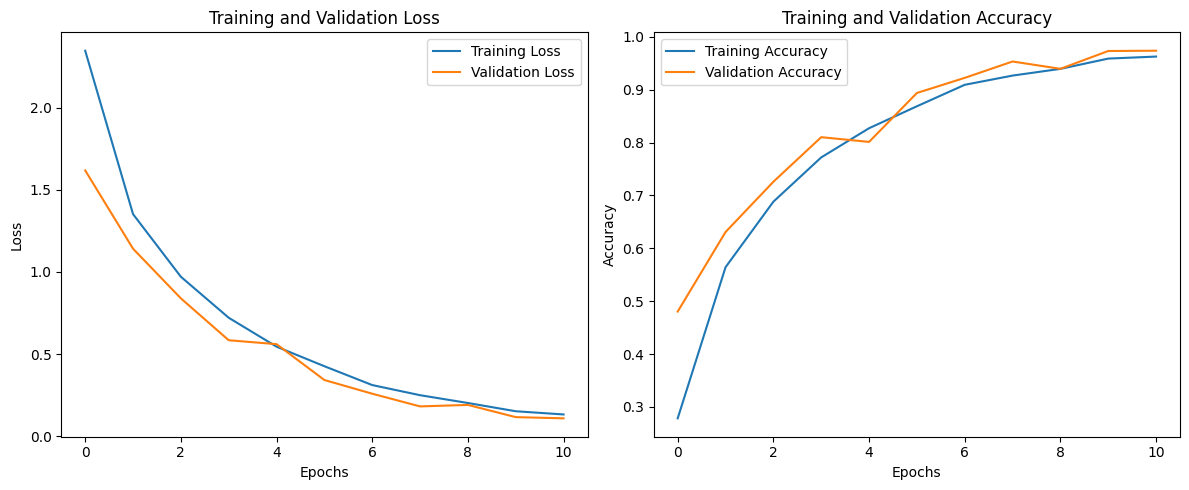

In [1]:

# 1E: Feedforward Neural Network using Sign Language MNIST

# 1. Import necessary packages

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.optimizers import Adam


# 2. Load training and testing data

train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

# Separate labels and images

y_train = train_data.iloc[:, 0].values
y_test = test_data.iloc[:, 0].values

x_train = train_data.iloc[:, 1:].values
x_test = test_data.iloc[:, 1:].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


# 3. Normalize the pixel values

x_train = x_train / 255.0
x_test = x_test / 255.0


# 4. Define FNN architecture

model = Sequential([
    Input(shape=(784,)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(25, activation='softmax')
])

model.summary()


# 5. Compile the model using Adam optimizer

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# 6. Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.2
)


# 7. Evaluate the network

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


# 8. Plot training loss and accuracy

plt.figure(figsize=(12, 5))

# Plot loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()
